In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Load and clean dataset
csv_files = list(Path("../data").glob("*.csv"))

if len(csv_files) != 1:
    raise ValueError(f"Expected one CSV file, found {len(csv_files)}")

df = pd.read_csv(csv_files[0])
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Recreate the original split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Data preparation complete.")

Training rows: 5634
Test rows: 1409
Data preparation complete.


Build both Candidate Models

In [2]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

def build_preprocessor(scale_numeric=False):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ])

lr_model = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(max_iter=1000))
])

rf_model = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

print("Both candidate models are ready.")

Both candidate models are ready.


Select the Model using Cross-Validation Results

In [3]:
cv_summary = pd.read_csv("../reports/day6_cv_summary.csv")

display(
    cv_summary[
        ["model", "f1_mean", "f1_std", "recall_mean", "roc_auc_mean"]
    ].round(4)
)

selected_name = (
    cv_summary.sort_values("f1_mean", ascending=False)
    .iloc[0]["model"]
)

candidate_models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}

selected_model = candidate_models[selected_name]

print("Selected model based on mean CV F1:", selected_name)

,model,f1_mean,f1_std,recall_mean,roc_auc_mean
0,Logistic Regression,0.5923,0.0331,0.5431,0.8461
1,Random Forest,0.6040,0.0267,0.6448,0.8224


Selected model based on mean CV F1: Random Forest


Fit the Selected Model and Evaluate

In [4]:
selected_model.fit(X_train, y_train)

y_pred = selected_model.predict(X_test)
y_prob = selected_model.predict_proba(X_test)[:, 1]

final_metrics = {
    "model": selected_name,
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1_score": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_prob)
}

final_metrics_df = pd.DataFrame([final_metrics])

display(final_metrics_df.round(4))

,model,accuracy,precision,recall,f1_score,roc_auc
0,Random Forest,0.7637,0.5482,0.623,0.5832,0.823


Generate final Evaluation Visuals

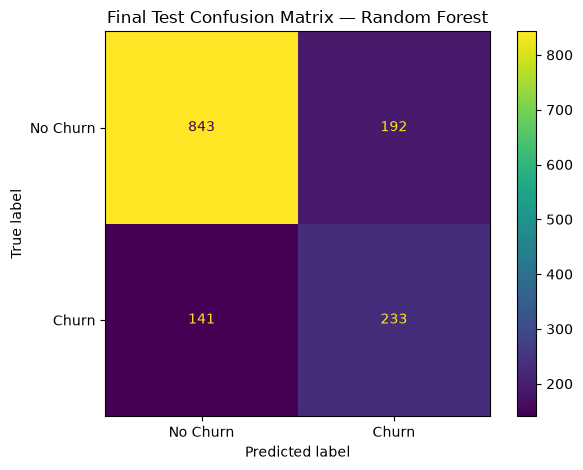

In [5]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    values_format="d"
)

plt.title(f"Final Test Confusion Matrix — {selected_name}")
plt.tight_layout()
plt.show()

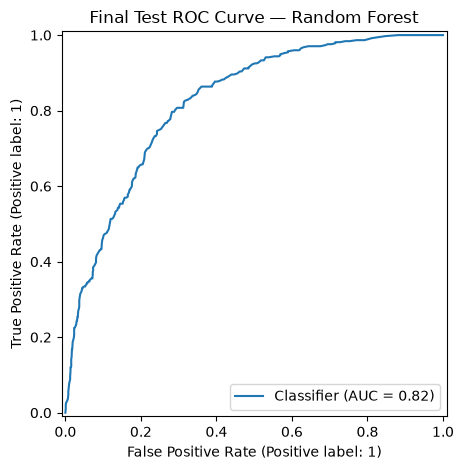

In [6]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title(f"Final Test ROC Curve — {selected_name}")
plt.tight_layout()
plt.show()

Classification Report

In [7]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn     0.8567    0.8145    0.8351      1035
       Churn     0.5482    0.6230    0.5832       374

    accuracy                         0.7637      1409
   macro avg     0.7025    0.7187    0.7091      1409
weighted avg     0.7748    0.7637    0.7682      1409



Save the Final Results

In [8]:
report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)

final_metrics_df.to_csv(
    report_dir / "day7_final_test_metrics.csv",
    index=False
)

final_cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    final_cm,
    index=["Actual_No_Churn", "Actual_Churn"],
    columns=["Predicted_No_Churn", "Predicted_Churn"]
)

cm_df.to_csv(
    report_dir / "day7_final_confusion_matrix.csv"
)

print("Final evaluation reports saved successfully.")

Final evaluation reports saved successfully.


# Week 1 Project Summary: Customer Churn Prediction

## Project Objective
Develop a machine-learning baseline to predict whether a telecommunications customer is likely to churn using customer account and service information.

## Work Completed
- Loaded and cleaned the dataset.
- Conducted exploratory data analysis and identified churn patterns.
- Built Logistic Regression and Random Forest pipelines.
- Evaluated classification metrics and confusion matrices.
- Explored prediction errors and decision-threshold trade-offs.
- Used stratified cross-validation to compare model performance.
- Evaluated the selected model on the held-out test set.

## Final Results
- Selected model: Random Forest
- Accuracy: 0.7637
- Precision: 0.5482
- Recall: 0.623
- F1 score: 0.5832
- ROC-AUC: 0.823


## Limitations
The results depend on the available dataset, selected features, and evaluation strategy. Predictive relationships do not prove causation, and performance on historical data does not guarantee performance on future customers.

## Future Improvements
- Tune hyperparameters using validation or cross-validation.
- Select decision thresholds using business costs and validation data.
- Evaluate calibration and performance across customer segments.
- Monitor performance if the model is eventually used on new data.
